In [1]:
import torch

inputs = torch.tensor(
    [
        [0.43, 0.15, 0.89],  # Your     (x^1)
        [0.55, 0.87, 0.66],  # journey  (x^2)
        [0.57, 0.85, 0.64],  # starts   (x^3)
        [0.22, 0.58, 0.33],  # with     (x^4)
        [0.77, 0.25, 0.10],  # one      (x^5)
        [0.05, 0.80, 0.55],  # step     (x^6)
    ]
)
query = inputs[1]  # The second input token serves as the query.

attn_scores_2 = torch.empty(inputs.shape[0])
for i, x_i in enumerate(inputs):
    attn_scores_2[i] = torch.dot(x_i, query)
print(attn_scores_2)

tensor([0.9544, 1.4950, 1.4754, 0.8434, 0.7070, 1.0865])


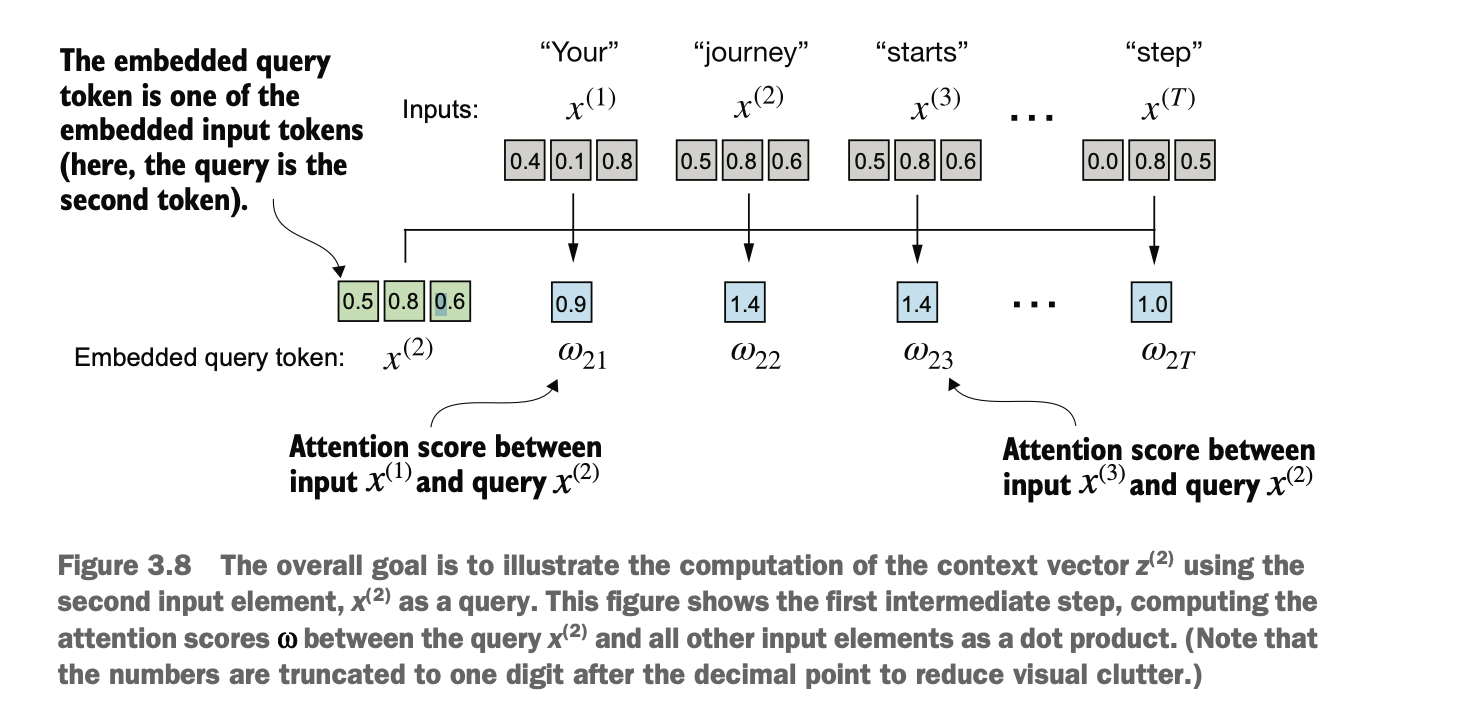


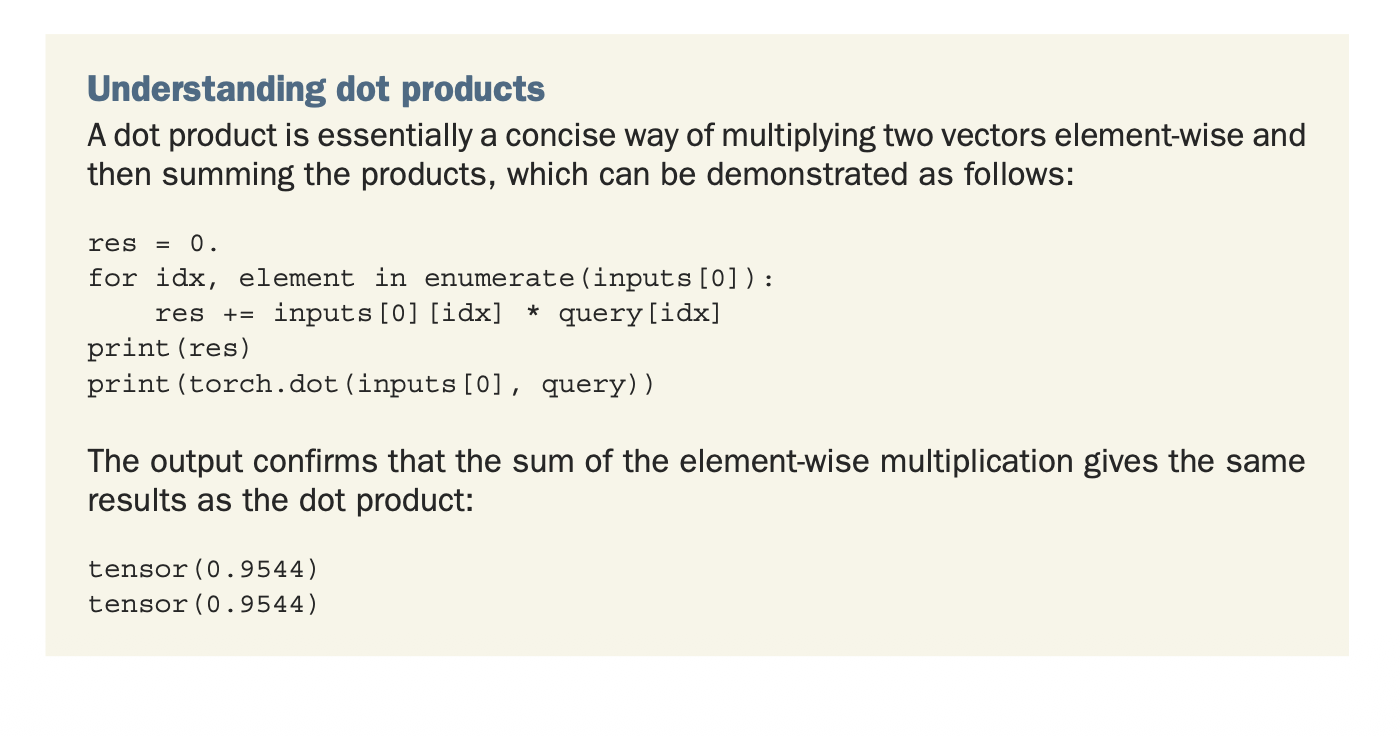


In [2]:
res = 0.0
for idx, element in enumerate(inputs[0]):
    res += inputs[0][idx] * query[idx]
print(res)
print(torch.dot(inputs[0], query))

tensor(0.9544)
tensor(0.9544)


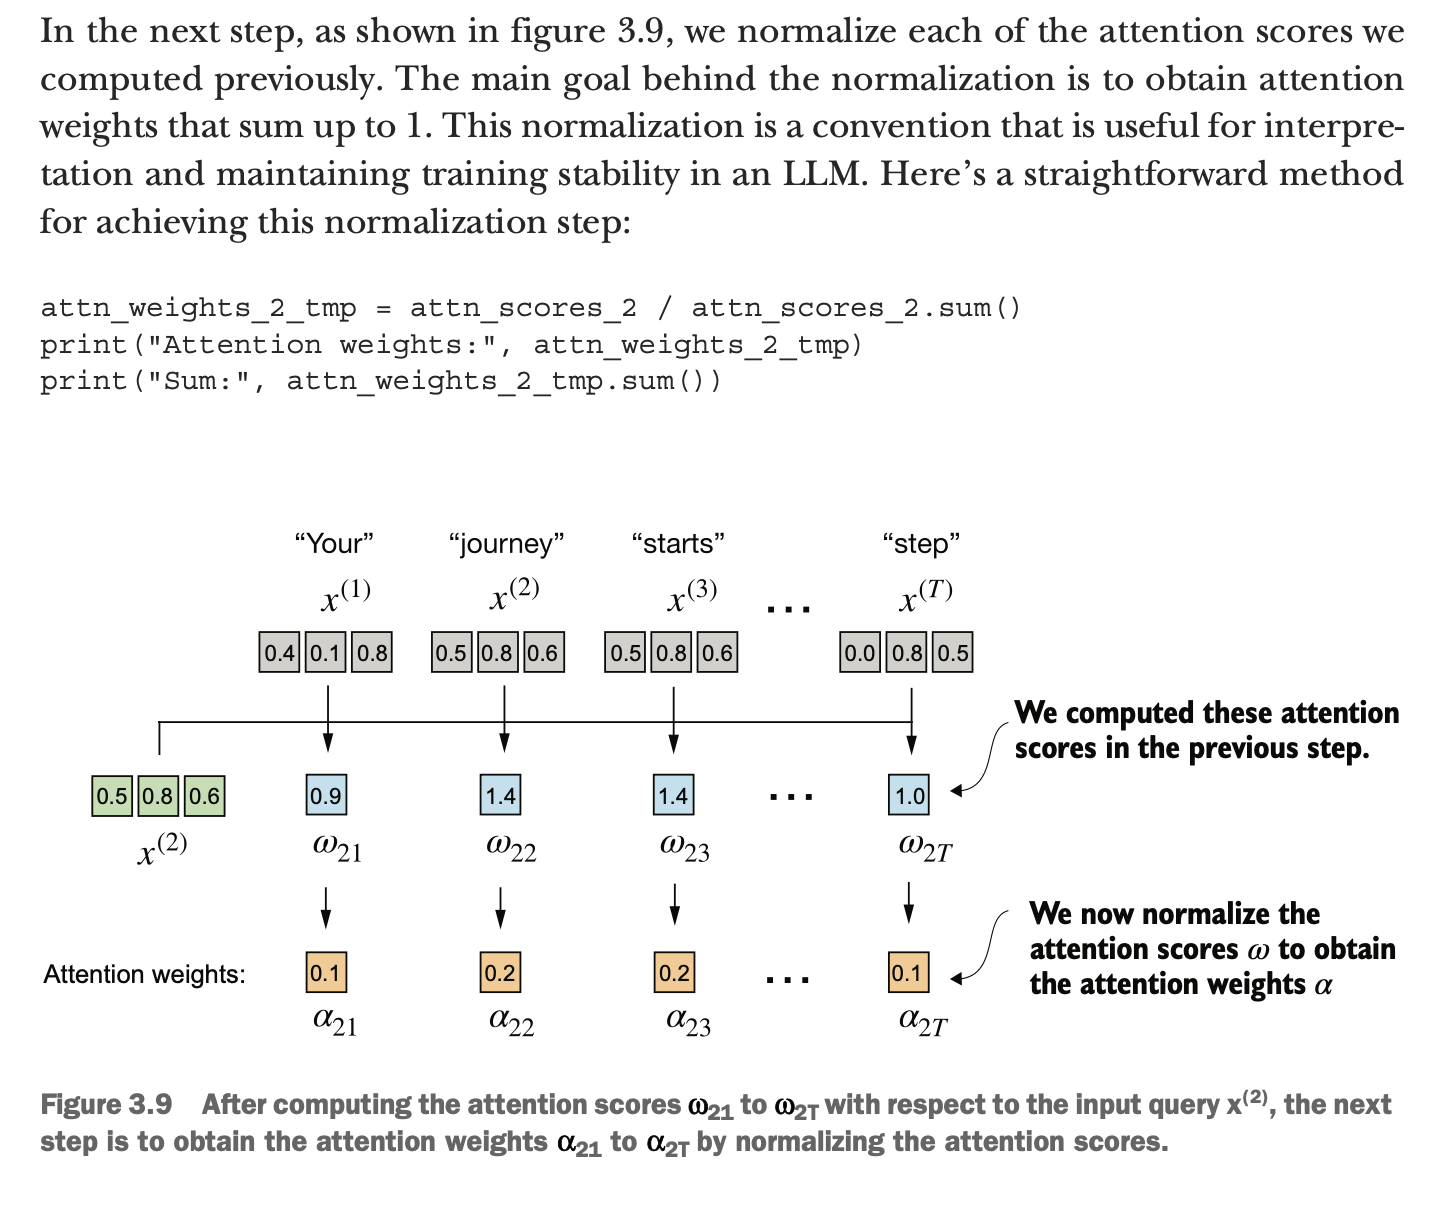


In [3]:
attn_weights_2_tmp = attn_scores_2 / attn_scores_2.sum()
print("Attention weights:", attn_weights_2_tmp)
print("Sum:", attn_weights_2_tmp.sum())

Attention weights: tensor([0.1455, 0.2278, 0.2249, 0.1285, 0.1077, 0.1656])
Sum: tensor(1.0000)


In [ ]:
# In practice, it’s more common and advisable to use the softmax function for normal-
# ization. This approach is better at managing extreme values and offers more favorable
# gradient properties during training. The following is a basic implementation of the
# softmax function for normalizing the attention scores:


def softmax_naive(x):
    return torch.exp(x) / torch.exp(x).sum(dim=0)


attn_weights_2_naive = softmax_naive(attn_scores_2)
print("Attention weights:", attn_weights_2_naive)
print("Sum:", attn_weights_2_naive.sum())

Attention weights: tensor([0.1385, 0.2379, 0.2333, 0.1240, 0.1082, 0.1581])
Sum: tensor(1.)


In [ ]:
#   Naive softmax implementation (softmax_naive) may encounter
# numerical instability problems, such as overflow and underflow, when dealing with
# large or small input values. Therefore, in practice, it’s advisable to use the PyTorch
# implementation of softmax, which has been extensively optimized for performance:

attn_weights_2 = torch.softmax(attn_scores_2, dim=0)
print("Attention weights:", attn_weights_2)
print("Sum:", attn_weights_2.sum())

Attention weights: tensor([0.1385, 0.2379, 0.2333, 0.1240, 0.1082, 0.1581])
Sum: tensor(1.)


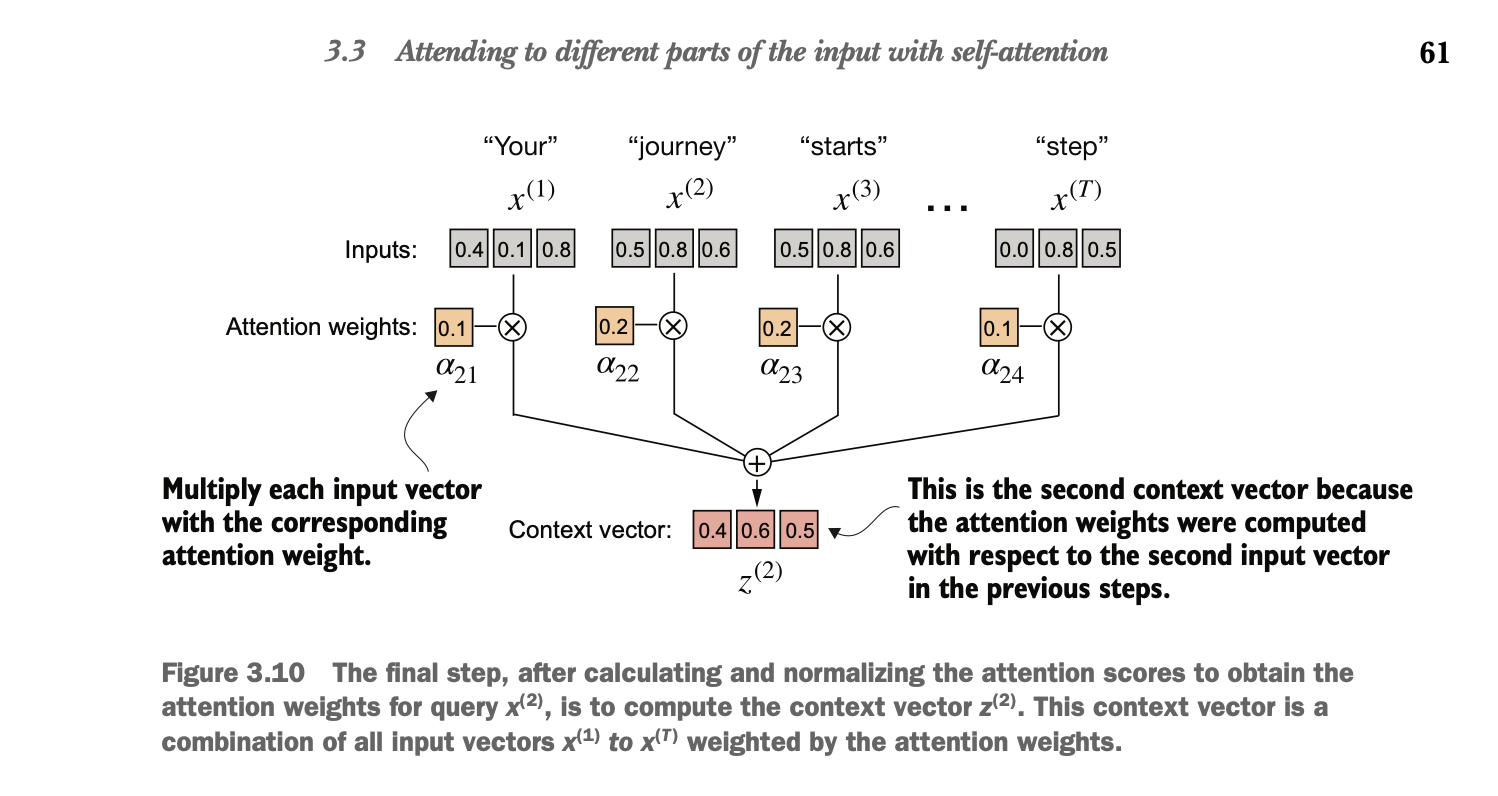


In [11]:
query = inputs[1]
context_vec_2 = torch.zeros(query.shape)
for i, x_i in enumerate(inputs):
    context_vec_2 += attn_weights_2[i] * x_i
print(context_vec_2)

tensor([0.4419, 0.6515, 0.5683])


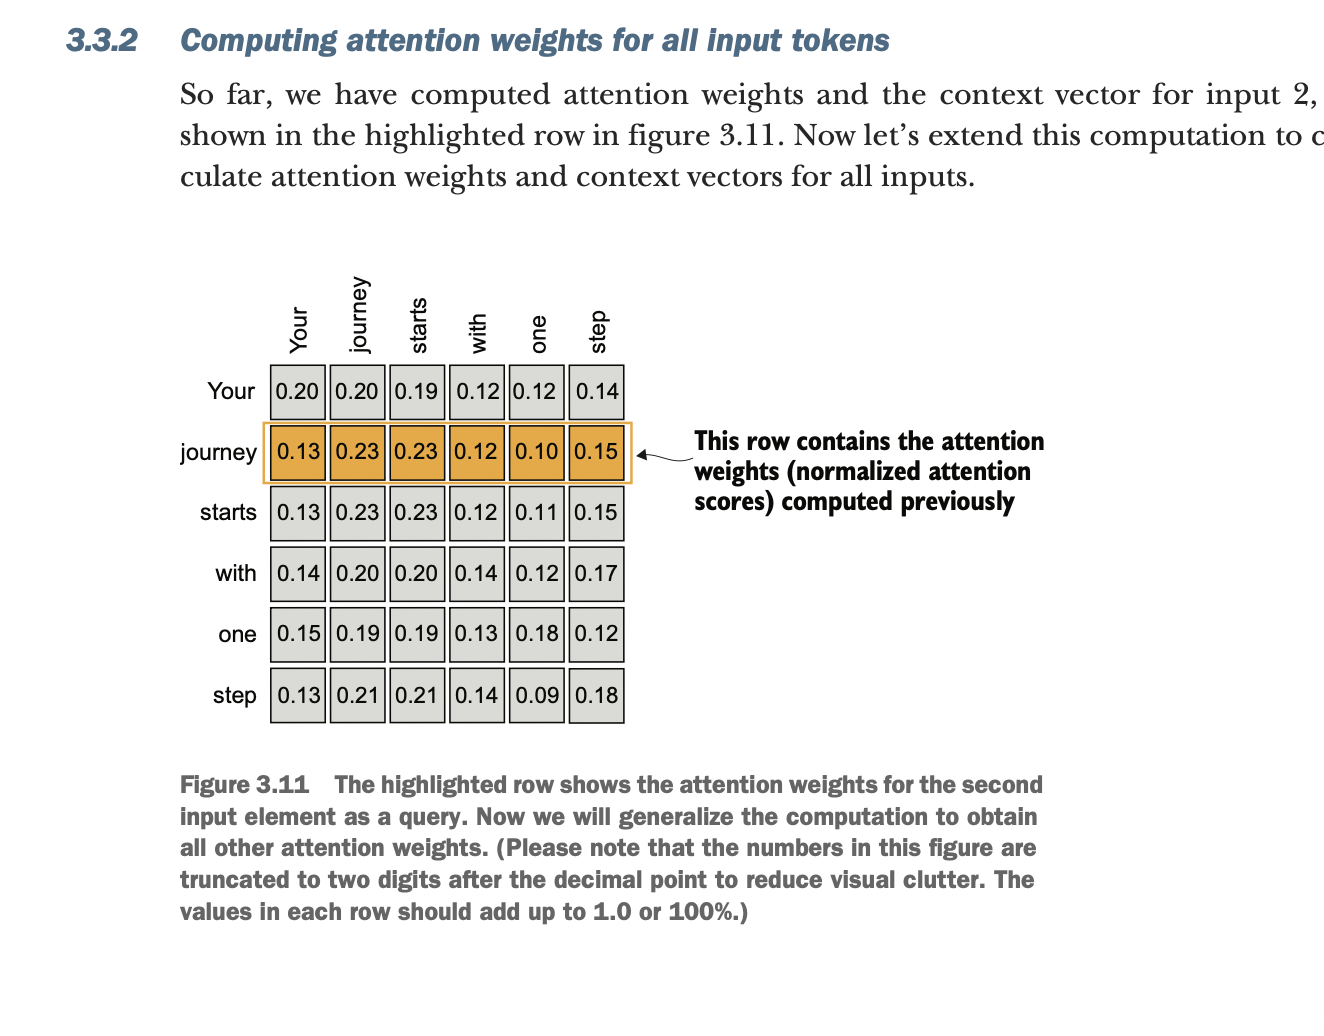